In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df = pd.read_csv('/content/KaggleV2-May-2016.csv')


valid_age_median = df.loc[df['Age'] >= 0, 'Age'].median()
df.loc[df['Age'] < 0, 'Age'] = valid_age_median

df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'], utc=True)
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay'], utc=True)

df['WaitingDays'] = (
    df['AppointmentDay'].dt.normalize() -
    df['ScheduledDay'].dt.normalize()
).dt.days

df['HealthConditionCount'] = (
    df['Hipertension'] +
    df['Diabetes'] +
    df['Alcoholism']
)

features = ['Age', 'WaitingDays', 'HealthConditionCount']

# Remove invalid waiting-time records
cluster_df = df[features].copy()
cluster_df = cluster_df[cluster_df['WaitingDays'] >= 0].dropna()

print("Dataset shape:", cluster_df.shape)
print(cluster_df.head())
print("\nMissing values:")
print(cluster_df.isnull().sum())

Dataset shape: (110522, 3)
   Age  WaitingDays  HealthConditionCount
0   62            0                     1
1   56            0                     0
2   62            0                     0
3    8            0                     0
4   56            0                     2

Missing values:
Age                     0
WaitingDays             0
HealthConditionCount    0
dtype: int64


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_df[features])

print("Scaled data shape:", X_scaled.shape)
print(pd.DataFrame(X_scaled, columns=features).describe().round(2))

Scaled data shape: (110522, 3)
             Age  WaitingDays  HealthConditionCount
count  110522.00    110522.00             110522.00
mean       -0.00         0.00                 -0.00
std         1.00         1.00                  1.00
min        -1.60        -0.67                 -0.50
25%        -0.83        -0.67                 -0.50
50%        -0.00        -0.41                 -0.50
75%         0.78         0.32                 -0.50
max         3.37        11.07                  4.52


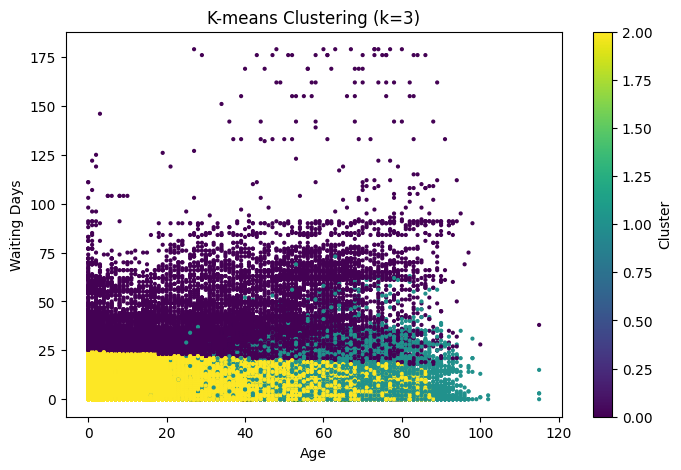

Cluster
0    16651
1    23807
2    70064
Name: count, dtype: int64


In [7]:
kmeans3 = KMeans(n_clusters=3, n_init=10, random_state=42)

cluster_df['Cluster'] = kmeans3.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
plt.scatter(
    cluster_df['Age'],
    cluster_df['WaitingDays'],
    c=cluster_df['Cluster'],
    cmap='viridis',
    s=4
)

plt.xlabel('Age')
plt.ylabel('Waiting Days')
plt.title('K-means Clustering (k=3)')
plt.colorbar(label='Cluster')
plt.show()

print(cluster_df['Cluster'].value_counts().sort_index())

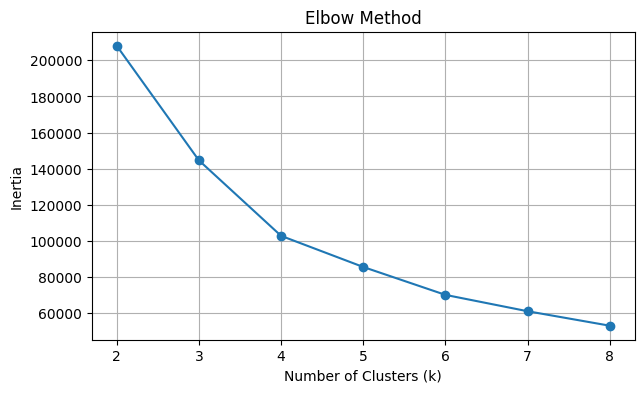

[(2, 208050.95200026355), (3, 144625.0904340881), (4, 102845.57182216442), (5, 85608.28561810228), (6, 70173.61759247778), (7, 61122.142183230055), (8, 53111.17132958719)]


In [8]:
inertias = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 9), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(range(2, 9))
plt.grid()
plt.show()

print(list(zip(range(2, 9), inertias)))

In [9]:
# final model fitted with k=4
final_kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
cluster_df['Cluster'] = final_kmeans.fit_predict(X_scaled)

# Average feature values in each cluster
cluster_summary = cluster_df.groupby('Cluster')[features].mean().round(2)

# Number of records in each cluster
cluster_summary['Count'] = cluster_df['Cluster'].value_counts()

print(cluster_summary)

           Age  WaitingDays  HealthConditionCount  Count
Cluster                                                 
0        50.49         5.21                  0.00  31542
1        14.55         5.60                  0.00  41618
2        59.42         6.59                  1.33  23651
3        36.17        41.74                  0.11  13711


In [10]:
cluster_names = {
    0: 'Middle-aged patients - Short wait',
    1: 'Younger patients - Short wait',
    2: 'Older patients - More health conditions',
    3: 'Adults - Long wait'
}

cluster_df['ClusterName'] = cluster_df['Cluster'].map(cluster_names)

print(cluster_df[['Age', 'WaitingDays','HealthConditionCount','ClusterName']].head())
print("\nCluster counts:")
print(cluster_df['ClusterName'].value_counts())

   Age  WaitingDays  HealthConditionCount  \
0   62            0                     1   
1   56            0                     0   
2   62            0                     0   
3    8            0                     0   
4   56            0                     2   

                               ClusterName  
0  Older patients - More health conditions  
1        Middle-aged patients - Short wait  
2        Middle-aged patients - Short wait  
3            Younger patients - Short wait  
4  Older patients - More health conditions  

Cluster counts:
ClusterName
Younger patients - Short wait              41618
Middle-aged patients - Short wait          31542
Older patients - More health conditions    23651
Adults - Long wait                         13711
Name: count, dtype: int64


K-means helped identify groups of patients based on age, waiting time, and recorded health conditions. These groups could help healthcare administrators explore patient patterns and plan appointment-related services. However, the clusters are exploratory groups, not medical categories, and their usefulness should be validated before making real healthcare decisions.

## 6. Cluster Interpretation and Usefulness

Based on the elbow method, I selected **k=4** because the inertia reduction becomes more gradual after four clusters.

The four clusters represent:
1. **Younger patients – Short wait:** Average age 14.55 years and average waiting time 5.60 days.
2. **Middle-aged patients – Short wait:** Average age 50.49 years and average waiting time 5.21 days.
3. **Older patients – More health conditions:** Average age 59.42 years and average of 1.33 recorded health conditions.
4. **Adults – Long wait:** Average age 36.17 years and average waiting time 41.74 days.

### Usefulness

K-means helped identify groups of patients based on age, waiting time, and recorded health conditions. These groups could help healthcare administrators explore patient patterns and plan appointment-related services. However, the clusters are exploratory groups, not medical categories, and their usefulness should be validated before making real healthcare decisions.